# Notebook 03 — ECL Baseline IFRS 9
## Comparaison Multi-Modèles Probabilité de Défaut + Calcul ECL sans Choc

**Objectif :** Entraîner et comparer 4 modèles de probabilité de défaut (LogReg / RF / XGBoost / LightGBM)
avec les métriques professionnelles standards du risque de crédit.
Sélectionner le modèle champion et calculer l'ECL baseline par stage et grade.

| Métrique | Seuil | Signification |
|---|---|---|
| AUC-ROC | > 0.70 | Discrimination globale |
| Gini | > 0.40 | Standard Bâle II |
| KS-Statistic | > 0.30 | Séparation défauts/non-défauts |
| Brier Score | < 0.10 | Calibration |
| PSI | < 0.10 | Stabilité train→test |
| Log-Loss | Minimiser | Calibration globale |


## Positionnement bancaire du notebook

**Role dans la plateforme**  
Modeliser la PD, comparer les modeles, calculer ECL IFRS 9 baseline par pret, stage et segment.

**Lecture expert bancaire**  
IFRS 9 exige une estimation de pertes attendues. La baseline sert de reference avant stress et avant impact capital.

**Sorties attendues**  
ecl_baseline.parquet, modeles PD, metriques, SHAP.

**Transition logique**  
Le notebook 04 relie les variables macro aux pertes via les modeles satellites.

In [1]:
import sys
sys.path.insert(0, '..')

import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

plt.rcParams['figure.figsize'] = (12, 5)
plt.rcParams['font.size'] = 11
sns.set_style('whitegrid')

OUTPUT_DIR = Path('../outputs')
OUTPUT_DIR.mkdir(exist_ok=True)

print('Imports OK')


Imports OK


---
## 1. Chargement du dataset nettoyé


In [2]:
def get_temporal_split(df, train_end="2015-12-31", val_end="2017-12-31"):
    """
    Split temporel sans .copy() pour éviter les MemoryError.
    Retourne des vues légères du DataFrame original.
    """
    train_mask = df["issue_d"] <= train_end
    val_mask   = (df["issue_d"] > train_end) & (df["issue_d"] <= val_end)
    test_mask  = df["issue_d"] > val_end

    train = df[train_mask]
    val   = df[val_mask]
    test  = df[test_mask]

    print(f"Split — Train: {len(train):,} | Val: {len(val):,} | Test: {len(test):,}")
    return train, val, test


# ─────────────────────────────────────────────
# CHARGEMENT
# ─────────────────────────────────────────────
import pathlib
import pandas as pd
import pyarrow.parquet as pq

try:
    from src.data_prep import POST_ORIGINATION_COLS
except (ImportError, AttributeError):
    POST_ORIGINATION_COLS = {
        'last_pymnt_d', 'out_prncp', 'total_rec_prncp', 'total_pymnt',
        'recoveries', 'collection_recovery_fee', 'loan_status'
    }


def get_origination_pd_features(df):
    """
    Fallback local implementation if src.data_prep.get_origination_pd_features
    is not available. Returns a sensible ordered list of origination features.
    """
    exclude = {
        'default_flag', 'stage', 'LGD', 'EAD', 'issue_d', 'loan_amnt', 'grade',
        'default_12m_observed', 'default_24m_observed'
    }
    # keep columns that are not post-origination and not in the exclude list
    cols = [c for c in df.columns if c not in POST_ORIGINATION_COLS and c not in exclude]

    # preferred canonical ordering (will pick existing ones)
    preferred = [
        'grade_num', 'subgrade_num', 'dti', 'revol_util', 'int_rate',
        'delinq_2yrs', 'log_annual_inc', 'credit_age_months', 'pub_rec',
        'open_acc', 'term_months', 'emp_length_num', 'verif_status_num',
        'ho_RENT', 'ho_OWN', 'UNRATE', 'GDPC1_growth', 'FEDFUNDS',
        'HY_SPREAD', 'CPI_change'
    ]
    features = [c for c in preferred if c in cols]
    # append any remaining candidate columns
    features += [c for c in cols if c not in features]
    return features

parquet_path = pathlib.Path('../outputs/loan_clean.parquet')

if not parquet_path.exists():
    print('loan_clean.parquet non trouvé, génération en cours...')
    from src.data_prep import build_clean_dataset
    df, macro = build_clean_dataset()
else:
    schema    = pq.read_schema(parquet_path)
    available = set(schema.names)
    needed = [
        'grade_num', 'subgrade_num', 'dti', 'revol_util', 'int_rate',
        'delinq_2yrs', 'log_annual_inc', 'credit_age_months', 'pub_rec',
        'open_acc', 'term_months', 'emp_length_num', 'verif_status_num',
        'ho_RENT', 'ho_OWN',
        'UNRATE', 'GDPC1_growth', 'FEDFUNDS', 'HY_SPREAD', 'CPI_change',
        'default_flag', 'stage', 'grade', 'LGD', 'EAD', 'issue_d', 'loan_amnt',
    ]
    cols = [c for c in needed if c in available]
    df   = pd.read_parquet(parquet_path, columns=cols)
    print(f'Dataset chargé depuis Parquet : {df.shape}')

# ─────────────────────────────────────────────
# DOWNCAST — économise 30-50% de RAM
# ─────────────────────────────────────────────
int_cols   = df.select_dtypes('int64').columns
float_cols = df.select_dtypes('float64').columns
df[int_cols]   = df[int_cols].astype('int32')
df[float_cols] = df[float_cols].astype('float32')
print(f"RAM après downcast : {df.memory_usage(deep=True).sum() / 1e9:.2f} GB")

# ─────────────────────────────────────────────
# FEATURES
# ─────────────────────────────────────────────
features = get_origination_pd_features(df)
print(f'Features PD ({len(features)}) : {features}')

# ─────────────────────────────────────────────
# SPLIT TEMPOREL — vues légères, zéro copie
# ─────────────────────────────────────────────
train_mask = df["issue_d"] <= "2015-12-31"
val_mask   = (df["issue_d"] > "2015-12-31") & (df["issue_d"] <= "2017-12-31")
test_mask  = df["issue_d"] > "2017-12-31"

print(f"Split — Train: {train_mask.sum():,} | Val: {val_mask.sum():,} | Test: {test_mask.sum():,}")

# ─────────────────────────────────────────────
# X / y — matérialise uniquement ce dont XGBoost a besoin
# ─────────────────────────────────────────────
X_train = df.loc[train_mask, features].fillna(0).astype('float32')
y_train = df.loc[train_mask, 'default_flag'].values

X_val   = df.loc[val_mask, features].fillna(0).astype('float32')
y_val   = df.loc[val_mask, 'default_flag'].values

X_test  = df.loc[test_mask, features].fillna(0).astype('float32')
y_test  = df.loc[test_mask, 'default_flag'].values

print(f'Déséquilibre dans train : {y_train.mean():.2%} de défauts')
print(f'scale_pos_weight        : {(y_train == 0).sum() / max((y_train == 1).sum(), 1):.1f}')


Dataset chargé depuis Parquet : (2260668, 27)
RAM après downcast : 0.26 GB
Features PD (20) : ['grade_num', 'subgrade_num', 'dti', 'revol_util', 'int_rate', 'delinq_2yrs', 'log_annual_inc', 'credit_age_months', 'pub_rec', 'open_acc', 'term_months', 'emp_length_num', 'verif_status_num', 'ho_RENT', 'ho_OWN', 'UNRATE', 'GDPC1_growth', 'FEDFUNDS', 'HY_SPREAD', 'CPI_change']
Split — Train: 887,440 | Val: 877,986 | Test: 495,242
Déséquilibre dans train : 17.18% de défauts
scale_pos_weight        : 4.8


## 1.b Contr?le anti-leakage des features

Les modeles PD utilisent desormais `get_origination_pd_features`, c'est-a-dire les variables disponibles a l'octroi ou au mois d'emission. Les variables post-origination restent reservees au calcul LGD/EAD et a la validation historique.


In [3]:
try:
    from src.data_prep import POST_ORIGINATION_COLS
except (ImportError, AttributeError):
    POST_ORIGINATION_COLS = {
        'last_pymnt_d', 'out_prncp', 'total_rec_prncp', 'total_pymnt',
        'recoveries', 'collection_recovery_fee', 'loan_status'
    }

leakage_cols = sorted(set(features).intersection(POST_ORIGINATION_COLS))
print('Features PD retenues :', features)
print('Colonnes post-origination détectées dans les features :', leakage_cols)
assert len(leakage_cols) == 0, 'Risque de data leakage dans les features PD'


Features PD retenues : ['grade_num', 'subgrade_num', 'dti', 'revol_util', 'int_rate', 'delinq_2yrs', 'log_annual_inc', 'credit_age_months', 'pub_rec', 'open_acc', 'term_months', 'emp_length_num', 'verif_status_num', 'ho_RENT', 'ho_OWN', 'UNRATE', 'GDPC1_growth', 'FEDFUNDS', 'HY_SPREAD', 'CPI_change']
Colonnes post-origination détectées dans les features : []


---
## 2. Entraînement des 4 modèles PD


In [4]:
from src.ecl_engine import train_pd_models

trained_models, results_df = train_pd_models(
    X_train, y_train, X_val, y_val, X_test, y_test,
    save=True
)



→ Entraînement LogReg...
  [WARN] Calibration échouée (The 'cv' parameter of CalibratedClassifierCV must be an int in the range [2, inf), an object implementing 'split' and 'get_n_splits', an iterable or None. Got 'prefit' instead.) — modèle non calibré conservé
  AUC=0.6735 | Gini=0.3470 | KS=0.2500 | Brier=0.2834 | PSI=0.0797

→ Entraînement RandomForest...
  [WARN] Calibration échouée (The 'cv' parameter of CalibratedClassifierCV must be an int in the range [2, inf), an object implementing 'split' and 'get_n_splits', an iterable or None. Got 'prefit' instead.) — modèle non calibré conservé
  AUC=0.6928 | Gini=0.3857 | KS=0.2899 | Brier=0.2082 | PSI=0.0674

→ Entraînement XGBoost...
  [WARN] Calibration échouée (The 'cv' parameter of CalibratedClassifierCV must be an int in the range [2, inf), an object implementing 'split' and 'get_n_splits', an iterable or None. Got 'prefit' instead.) — modèle non calibré conservé
  AUC=0.6742 | Gini=0.3484 | KS=0.2520 | Brier=0.4029 | PSI=0.1020


---
## 3. Tableau comparatif des métriques professionnelles


In [5]:
def highlight_best(df_metrics):
    try:
        from importlib.util import find_spec
        if find_spec('jinja2') is None:
            raise ImportError('jinja2 not available')

        higher_better = ['AUC-ROC', 'Gini', 'KS']
        lower_better  = ['Brier', 'PSI', 'LogLoss']

        styled = df_metrics.style.set_table_styles([
            {'selector': 'th', 'props': [('background-color', '#2c3e50'),
                                          ('color', 'white'),
                                          ('font-weight', 'bold'),
                                          ('text-align', 'center'),
                                          ('padding', '8px')]},
            {'selector': 'td', 'props': [('text-align', 'center'), ('padding', '6px')]},
            {'selector': 'tr:hover', 'props': [('background-color', '#f0f0f0')]},
        ]).format(precision=4)

        for col in higher_better:
            if col in df_metrics.columns:
                styled = styled.highlight_max(subset=[col], color='#90EE90')
        for col in lower_better:
            if col in df_metrics.columns:
                styled = styled.highlight_min(subset=[col], color='#90EE90')

        return styled

    except (ImportError, AttributeError):
        # Fallback sans jinja2 : affichage console propre
        print(df_metrics.to_string(index=True))
        return None


# ─────────────────────────────────────────────
# AFFICHAGE
# ─────────────────────────────────────────────
print('\n=== Tableau Comparatif des Métriques Professionnelles ===')
print('(Vert = meilleur sur chaque colonne)\n')

result = highlight_best(results_df)
if result is not None:
    display(result)

# Seuils réglementaires
print('\nSeuils réglementaires :')
print('  AUC > 0.70 | Gini > 0.40 | KS > 0.30 | Brier < 0.10 | PSI < 0.10')

champion = results_df['AUC-ROC'].idxmax()
print(f'\n🏆 Modèle champion sélectionné : {champion}')



=== Tableau Comparatif des Métriques Professionnelles ===
(Vert = meilleur sur chaque colonne)



,AUC-ROC,Gini,KS,Brier,PSI,LogLoss
Model,,,,,,
LogReg,0.6735,0.3470,0.2500,0.2834,0.0797,0.7793
RandomForest,0.6928,0.3857,0.2899,0.2082,0.0674,0.5990
XGBoost,0.6742,0.3484,0.2520,0.4029,0.1020,1.0585
LightGBM,0.6808,0.3617,0.2643,0.2291,0.0090,0.6447



Seuils réglementaires :
  AUC > 0.70 | Gini > 0.40 | KS > 0.30 | Brier < 0.10 | PSI < 0.10

🏆 Modèle champion sélectionné : RandomForest


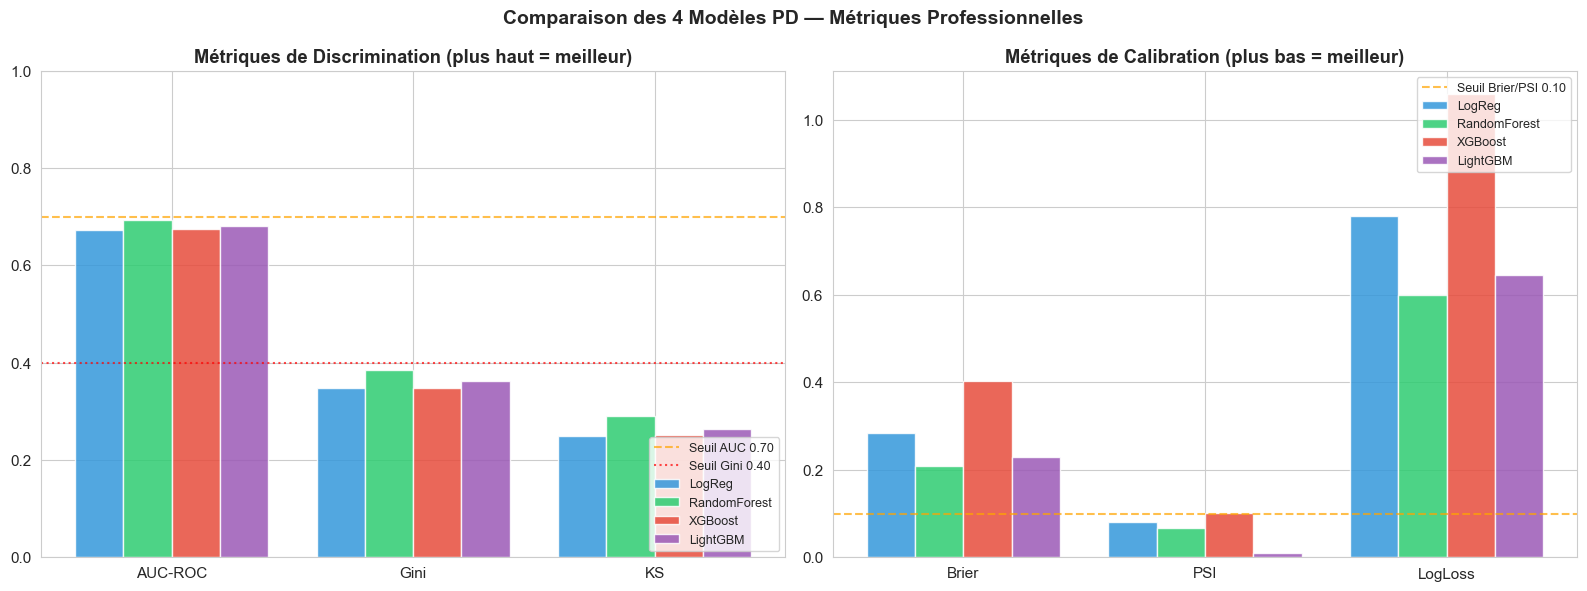

In [6]:
# Visualisation radar des métriques
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Barplot comparatif par métrique
metrics_to_plot = ['AUC-ROC', 'Gini', 'KS']
x = np.arange(len(metrics_to_plot))
width = 0.2
colors = ['#3498db', '#2ecc71', '#e74c3c', '#9b59b6']
models_list = results_df.index.tolist()

for i, (name, color) in enumerate(zip(models_list, colors)):
    vals = [results_df.loc[name, m] for m in metrics_to_plot]
    axes[0].bar(x + i * width, vals, width, label=name, color=color, alpha=0.85)

axes[0].axhline(0.70, color='orange', linestyle='--', linewidth=1.5, alpha=0.7, label='Seuil AUC 0.70')
axes[0].axhline(0.40, color='red', linestyle=':', linewidth=1.5, alpha=0.7, label='Seuil Gini 0.40')
axes[0].set_xticks(x + width * (len(models_list)-1) / 2)
axes[0].set_xticklabels(metrics_to_plot)
axes[0].set_title('Métriques de Discrimination (plus haut = meilleur)', fontweight='bold')
axes[0].legend(loc='lower right', fontsize=9)
axes[0].set_ylim(0, 1.0)

# Métriques de calibration
metrics_calib = ['Brier', 'PSI', 'LogLoss']
x2 = np.arange(len(metrics_calib))
for i, (name, color) in enumerate(zip(models_list, colors)):
    vals = [results_df.loc[name, m] for m in metrics_calib]
    axes[1].bar(x2 + i * width, vals, width, label=name, color=color, alpha=0.85)

axes[1].axhline(0.10, color='orange', linestyle='--', linewidth=1.5, alpha=0.7, label='Seuil Brier/PSI 0.10')
axes[1].set_xticks(x2 + width * (len(models_list)-1) / 2)
axes[1].set_xticklabels(metrics_calib)
axes[1].set_title('Métriques de Calibration (plus bas = meilleur)', fontweight='bold')
axes[1].legend(loc='upper right', fontsize=9)

plt.suptitle('Comparaison des 4 Modèles PD — Métriques Professionnelles', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'fig_13_model_comparison.png', dpi=150, bbox_inches='tight')
plt.show()


---
## 4. Courbes ROC superposées


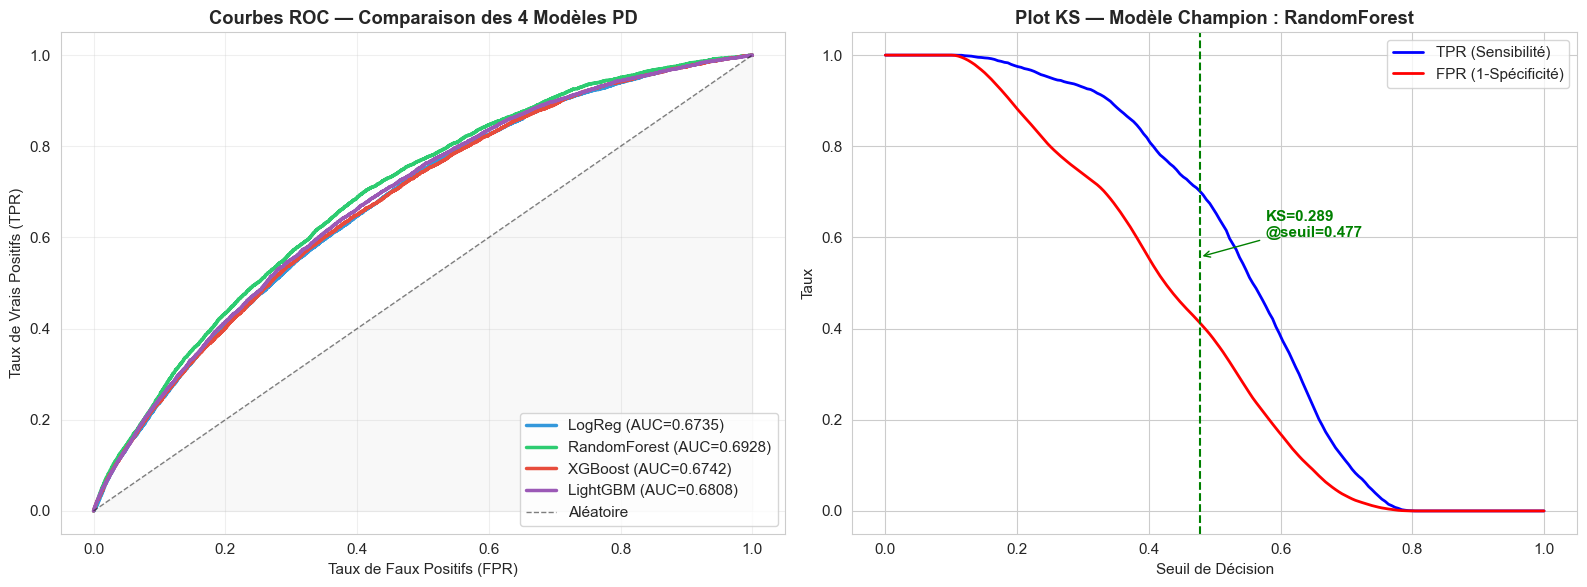

In [7]:
from src.ecl_engine import get_roc_data

roc_data = get_roc_data(trained_models, X_test, y_test)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Courbes ROC
colors = ['#3498db', '#2ecc71', '#e74c3c', '#9b59b6']
for (name, data), color in zip(roc_data.items(), colors):
    axes[0].plot(data['fpr'], data['tpr'], linewidth=2.5, color=color,
                  label=f"{name} (AUC={data['auc']:.4f})")

axes[0].plot([0,1], [0,1], 'k--', linewidth=1, alpha=0.5, label='Aléatoire')
axes[0].fill_between([0,1], [0,1], alpha=0.05, color='gray')
axes[0].set_xlabel('Taux de Faux Positifs (FPR)')
axes[0].set_ylabel('Taux de Vrais Positifs (TPR)')
axes[0].set_title('Courbes ROC — Comparaison des 4 Modèles PD', fontweight='bold')
axes[0].legend(loc='lower right')
axes[0].grid(True, alpha=0.3)

# KS Plot pour le modèle champion
champion_model = trained_models[champion]
y_prob_champion = champion_model.predict_proba(X_test)[:, 1]

thresholds = np.linspace(0, 1, 200)
tpr_arr, fpr_arr = [], []
for t in thresholds:
    y_pred = (y_prob_champion >= t).astype(int)
    tp = ((y_pred == 1) & (y_test == 1)).sum()
    fn = ((y_pred == 0) & (y_test == 1)).sum()
    fp = ((y_pred == 1) & (y_test == 0)).sum()
    tn = ((y_pred == 0) & (y_test == 0)).sum()
    tpr_arr.append(tp / max(tp + fn, 1))
    fpr_arr.append(fp / max(fp + tn, 1))

tpr_arr, fpr_arr = np.array(tpr_arr), np.array(fpr_arr)
ks_val = np.max(np.abs(tpr_arr - fpr_arr))
ks_idx = np.argmax(np.abs(tpr_arr - fpr_arr))

axes[1].plot(thresholds, tpr_arr, label='TPR (Sensibilité)', color='blue', linewidth=2)
axes[1].plot(thresholds, fpr_arr, label='FPR (1-Spécificité)', color='red', linewidth=2)
axes[1].axvline(thresholds[ks_idx], color='green', linestyle='--', linewidth=1.5)
axes[1].annotate(f'KS={ks_val:.3f}\n@seuil={thresholds[ks_idx]:.3f}',
                  xy=(thresholds[ks_idx], (tpr_arr[ks_idx]+fpr_arr[ks_idx])/2),
                  xytext=(thresholds[ks_idx]+0.1, 0.6),
                  arrowprops=dict(arrowstyle='->', color='green'),
                  color='green', fontweight='bold')
axes[1].set_xlabel('Seuil de Décision')
axes[1].set_ylabel('Taux')
axes[1].set_title(f'Plot KS — Modèle Champion : {champion}', fontweight='bold')
axes[1].legend()

plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'fig_14_roc_ks.png', dpi=150, bbox_inches='tight')
plt.show()


---
## 5. Walk-Forward Validation (Stabilité Temporelle)


Walk-forward validation (2011-2018)...
  [2011] Train=20,814 | Test=21,721 | AUC=0.6785
  [2012] Train=42,535 | Test=53,367 | AUC=0.6563
  [2013] Train=95,902 | Test=134,814 | AUC=0.6723
  [2014] Train=230,716 | Test=235,629 | AUC=0.6874
  [2015] Train=466,345 | Test=421,095 | AUC=0.6965
  [2016] Train=887,440 | Test=434,407 | AUC=0.6913
  [2017] Train=1,321,847 | Test=443,579 | AUC=0.6985
  [2018] Train=1,765,426 | Test=495,242 | AUC=0.6664


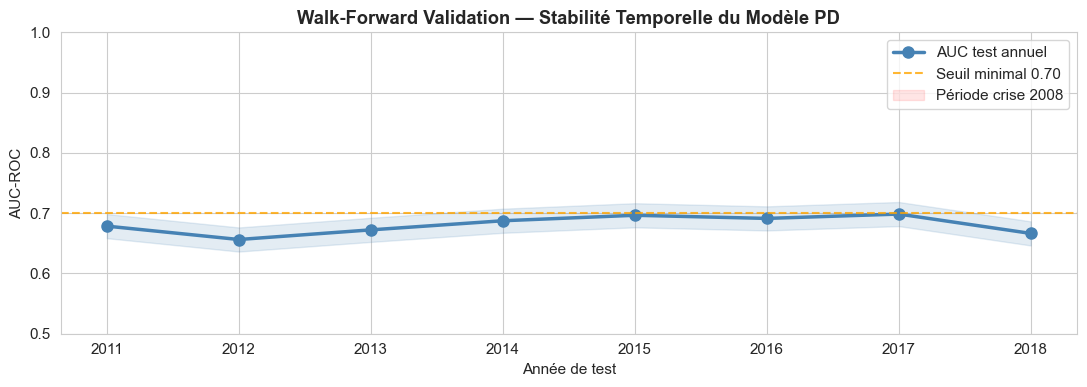


AUC moyen : 0.6809
AUC min   : 0.6563 (année 2012)
AUC max   : 0.6985


In [8]:
from src.ecl_engine import walk_forward_validation

print('Walk-forward validation (2011-2018)...')
wf_results = walk_forward_validation(df, features)

if len(wf_results) > 0:
    plt.figure(figsize=(11, 4))
    plt.plot(wf_results['test_year'], wf_results['AUC'], 'o-',
             color='steelblue', linewidth=2.5, markersize=8, label='AUC test annuel')
    plt.axhline(0.70, color='orange', linestyle='--', alpha=0.8, label='Seuil minimal 0.70')
    plt.axhspan(2008, 2010, alpha=0.1, color='red', label='Période crise 2008')
    plt.fill_between(wf_results['test_year'], wf_results['AUC'] - 0.02,
                      wf_results['AUC'] + 0.02, alpha=0.15, color='steelblue')
    plt.xlabel('Année de test')
    plt.ylabel('AUC-ROC')
    plt.title('Walk-Forward Validation — Stabilité Temporelle du Modèle PD', fontweight='bold')
    plt.legend()
    plt.ylim(0.5, 1.0)
    plt.tight_layout()
    plt.savefig(OUTPUT_DIR / 'fig_15_walk_forward.png', dpi=150, bbox_inches='tight')
    plt.show()
    
    print(f"\nAUC moyen : {wf_results['AUC'].mean():.4f}")
    print(f"AUC min   : {wf_results['AUC'].min():.4f} (année {wf_results.loc[wf_results['AUC'].idxmin(), 'test_year']})")
    print(f"AUC max   : {wf_results['AUC'].max():.4f}")


---
## 6. SHAP Values — Interprétabilité du Modèle Champion


<Figure size 1000x700 with 0 Axes>

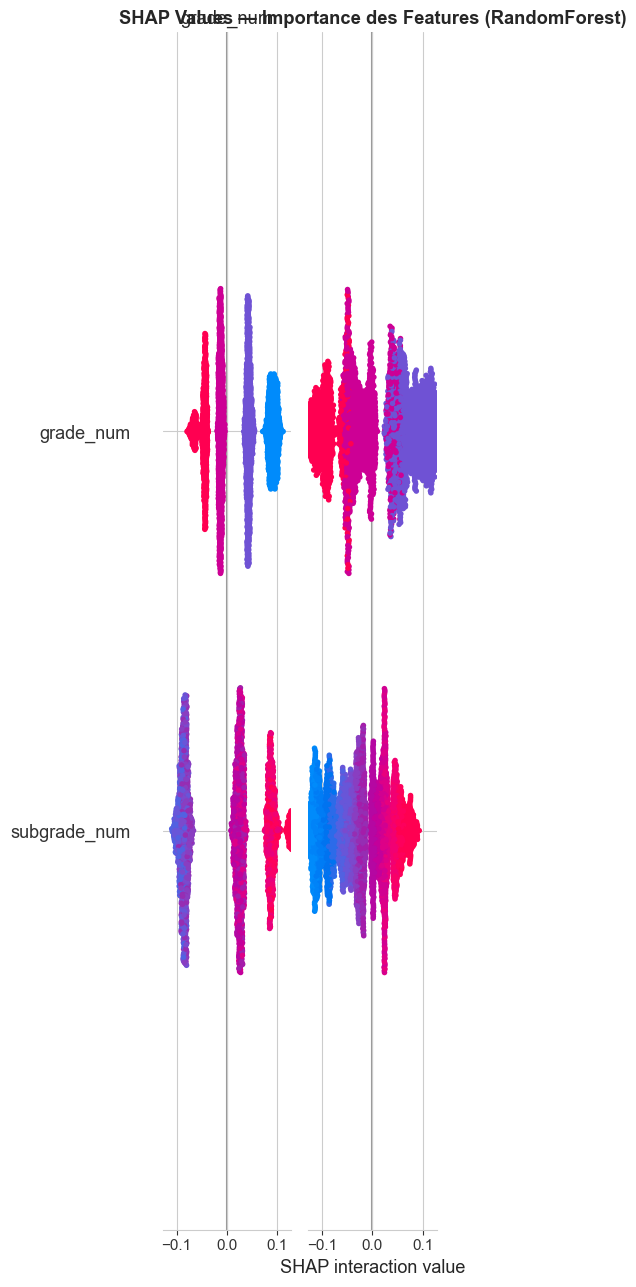

<Figure size 1000x600 with 0 Axes>

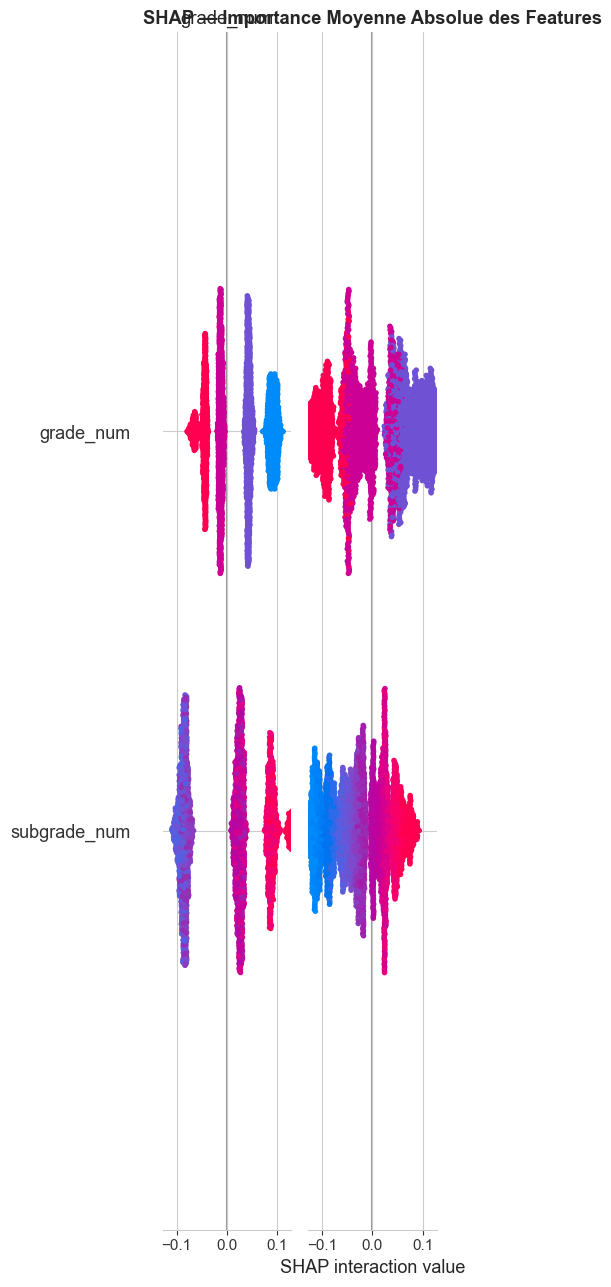

[WARN] SHAP dependence plot skipped: all the input array dimensions except for the concatenation axis must match exactly, but along dimension 1, the array at index 0 has size 2 and the array at index 1 has size 50


<Figure size 900x500 with 0 Axes>

In [9]:
import shap

# Échantillon de 5000 prêts pour la rapidité
sample_idx = X_test.sample(min(5000, len(X_test)), random_state=42).index
X_sample = X_test.loc[sample_idx]

champion_model = trained_models[champion]
if hasattr(champion_model, 'estimators_') or 'XGB' in type(champion_model).__name__ or 'LGBM' in type(champion_model).__name__ or 'LightGBM' in type(champion_model).__name__:
    explainer = shap.TreeExplainer(champion_model)
    shap_vals = explainer.shap_values(X_sample)
    if isinstance(shap_vals, list):
        shap_vals = shap_vals[1]
    shap_result = {'explainer': explainer, 'shap_values': shap_vals, 'X_sample': X_sample}
else:
    from src.ecl_engine import compute_shap_values
    shap_result = compute_shap_values(champion_model, X_sample, champion)

if shap_result:
    shap_vals = shap_result['shap_values']
    
    # Global feature importance (beeswarm)
    plt.figure(figsize=(10, 7))
    shap.summary_plot(shap_vals, X_sample, max_display=15,
                       show=False, plot_type='dot')
    plt.title(f'SHAP Values — Importance des Features ({champion})', fontweight='bold')
    plt.tight_layout()
    plt.savefig(OUTPUT_DIR / 'fig_16_shap_beeswarm.png', dpi=150, bbox_inches='tight')
    plt.show()
    
    # Bar plot SHAP moyen
    plt.figure(figsize=(10, 6))
    shap.summary_plot(shap_vals, X_sample, max_display=15,
                       show=False, plot_type='bar')
    plt.title(f'SHAP — Importance Moyenne Absolue des Features', fontweight='bold')
    plt.tight_layout()
    plt.savefig(OUTPUT_DIR / 'fig_17_shap_bar.png', dpi=150, bbox_inches='tight')
    plt.show()
    
    # SHAP dependence plot : UNRATE → effet sur PD
    if 'UNRATE' in features:
        try:
            plt.figure(figsize=(9, 5))
            shap.dependence_plot('UNRATE', shap_vals, X_sample, show=False)
            plt.title('SHAP Dependence : Impact du Chômage (UNRATE) sur la PD', fontweight='bold')
            plt.tight_layout()
            plt.savefig(OUTPUT_DIR / 'fig_18_shap_unrate.png', dpi=150, bbox_inches='tight')
            plt.show()
        except Exception as exc:
            print(f"[WARN] SHAP dependence plot skipped: {exc}")


---
## 7. Calcul de l'ECL Baseline IFRS 9


In [10]:
import importlib
import src.ecl_engine as ecl_engine
importlib.reload(ecl_engine)
from src.ecl_engine import compute_ecl_baseline

# ECL sur l'ensemble du portefeuille
df_ecl = compute_ecl_baseline(df, trained_models[champion], features)

# Sauvegarde
df_ecl[['loan_amnt', 'grade', 'stage', 'default_flag', 'PD_pred', 'LGD', 'EAD', 'ECL_ifrs9']].to_parquet(
    OUTPUT_DIR / 'ecl_baseline.parquet', index=False
)
print('ECL baseline sauvegardé : outputs/ecl_baseline.parquet')



=== ECL Baseline IFRS 9 ===
ECL Total     : $3,803.04 M
EAD Total     : $34.00 Mrd
Coverage Ratio: 11.18%
PD Moyenne    : 45.27%
LGD Médiane   : 58.96%

ECL par Stage :
           ECL_M       EAD_M  PD_moy  LGD_moy  nb_prets  Coverage
stage                                                            
1      2150.6571  29500.8788  0.4387   0.5887   1972587    0.0729
2       146.2982    429.4813  0.5327   0.6172     25634    0.3406
3      1506.0826   4073.8485  0.5503   0.6251    262447    0.3697

ECL par Grade (A → G) :
grade
A     239.58
B     708.76
C    1174.25
D     861.92
E     524.99
F     218.62
G      74.92
ECL baseline sauvegardé : outputs/ecl_baseline.parquet



=== ECL Baseline IFRS 9 ===
ECL Total     : $3,803.04 M
EAD Total     : $34.00 Mrd
Coverage Ratio: 11.18%
PD Moyenne    : 45.27%
LGD Médiane   : 58.96%

ECL par Stage :
           ECL_M       EAD_M  PD_moy  LGD_moy  nb_prets  Coverage
stage                                                            
1      2150.6571  29500.8788  0.4387   0.5887   1972587    0.0729
2       146.2982    429.4813  0.5327   0.6172     25634    0.3406
3      1506.0826   4073.8485  0.5503   0.6251    262447    0.3697

ECL par Grade (A → G) :
grade
A     239.58
B     708.76
C    1174.25
D     861.92
E     524.99
F     218.62
G      74.92


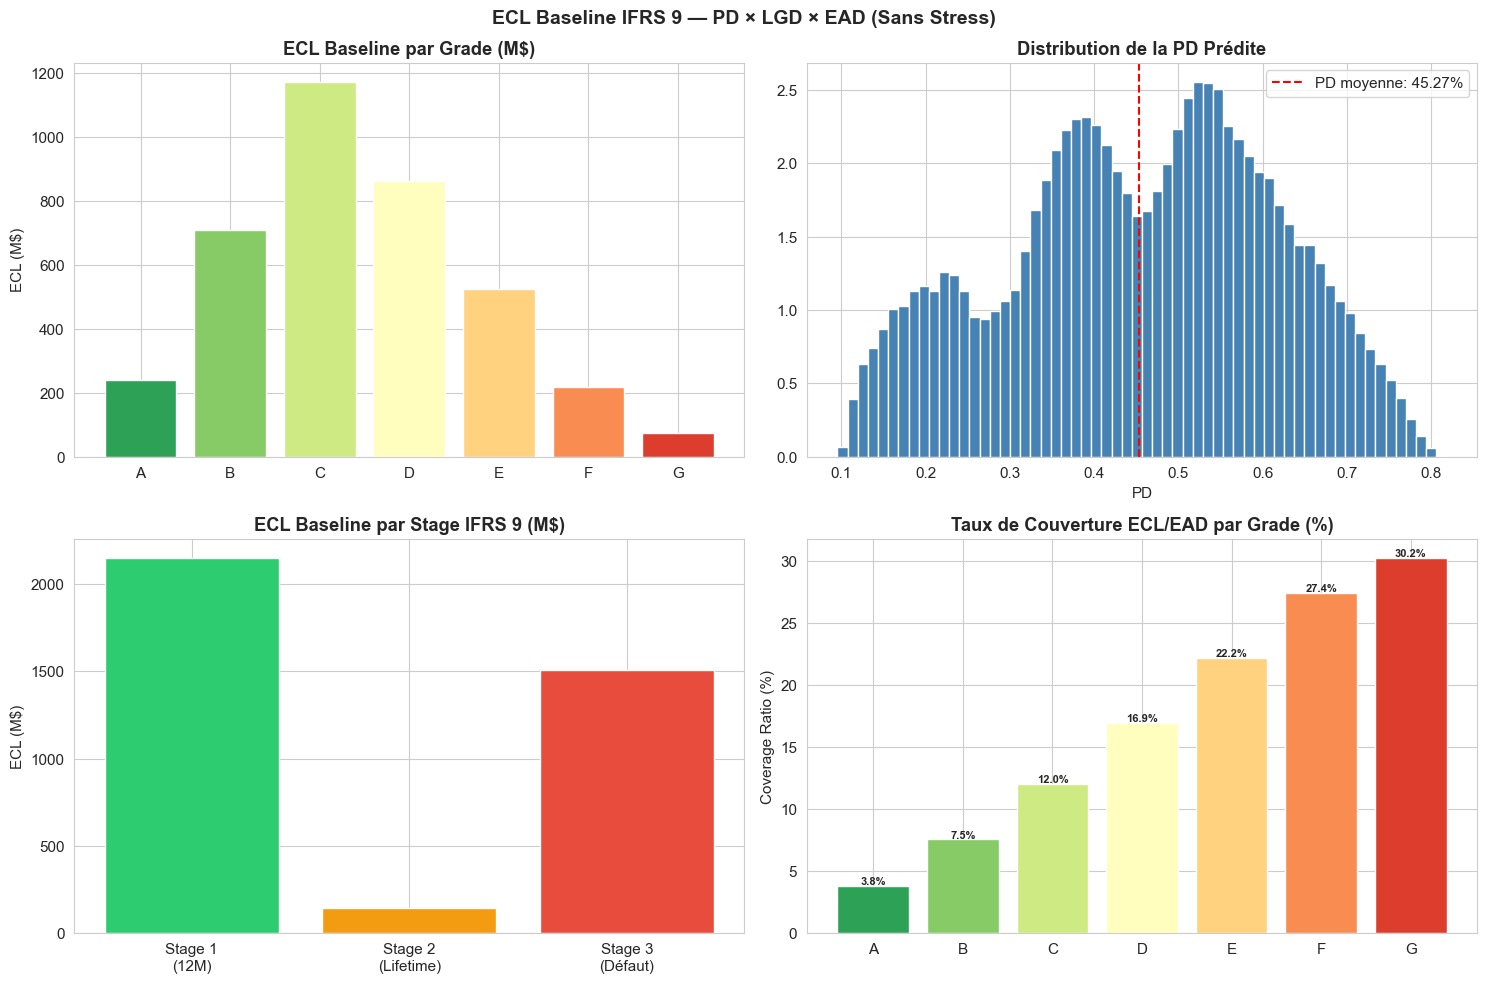


=== Notebook 02 terminé ===
Modèle champion : RandomForest
ECL Total  : $3,803.04 M
Coverage   : 11.18%


In [11]:
# Visualisation ECL Baseline
df_ecl = None
if 'df_ecl' not in globals() or df_ecl is None:
    import importlib
    import src.ecl_engine as ecl_engine
    importlib.reload(ecl_engine)
    from src.ecl_engine import compute_ecl_baseline
    df_ecl = compute_ecl_baseline(df, trained_models[champion], features)

fig, axes = plt.subplots(2, 2, figsize=(15, 10))

# ECL par grade
ecl_grade = df_ecl.groupby('grade')['ECL_ifrs9'].sum() / 1e6
ecl_grade = ecl_grade.reindex(['A','B','C','D','E','F','G'])
palette = sns.color_palette('RdYlGn_r', 7)
axes[0,0].bar(ecl_grade.index, ecl_grade, color=palette, edgecolor='white')
axes[0,0].set_title('ECL Baseline par Grade (M$)', fontweight='bold')
axes[0,0].set_ylabel('ECL (M$)')

# Distribution PD prédite
axes[0,1].hist(df_ecl['PD_pred'], bins=60, color='steelblue', edgecolor='white', density=True)
axes[0,1].axvline(df_ecl['PD_pred'].mean(), color='red', linestyle='--',
                   label=f"PD moyenne: {df_ecl['PD_pred'].mean():.2%}")
axes[0,1].set_title('Distribution de la PD Prédite', fontweight='bold')
axes[0,1].set_xlabel('PD')
axes[0,1].legend()

# ECL par Stage
ecl_stage = df_ecl.groupby('stage')['ECL_ifrs9'].sum() / 1e6
stage_labels = {1: 'Stage 1\n(12M)', 2: 'Stage 2\n(Lifetime)', 3: 'Stage 3\n(Défaut)'}
stage_colors = ['#2ecc71', '#f39c12', '#e74c3c']
stages = [1, 2, 3]
axes[1,0].bar([stage_labels[s] for s in stages],
               [ecl_stage.get(s, 0) for s in stages],
               color=stage_colors, edgecolor='white')
axes[1,0].set_title('ECL Baseline par Stage IFRS 9 (M$)', fontweight='bold')
axes[1,0].set_ylabel('ECL (M$)')

# Coverage ratio par grade
coverage = df_ecl.groupby('grade').apply(
    lambda x: x['ECL_ifrs9'].sum() / x['EAD'].sum() if x['EAD'].sum() > 0 else 0
) * 100
coverage = coverage.reindex(['A','B','C','D','E','F','G'])
axes[1,1].bar(coverage.index, coverage, color=palette, edgecolor='white')
axes[1,1].set_title('Taux de Couverture ECL/EAD par Grade (%)', fontweight='bold')
axes[1,1].set_ylabel('Coverage Ratio (%)')
for i, v in enumerate(coverage):
    if not np.isnan(v):
        axes[1,1].text(i, v + 0.1, f'{v:.1f}%', ha='center', fontsize=8, fontweight='bold')

plt.suptitle('ECL Baseline IFRS 9 — PD × LGD × EAD (Sans Stress)', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'fig_19_ecl_baseline.png', dpi=150, bbox_inches='tight')
plt.show()

print('\n=== Notebook 02 terminé ===')
print(f'Modèle champion : {champion}')
print(f"ECL Total  : ${df_ecl['ECL_ifrs9'].sum()/1e6:,.2f} M")
print(f"Coverage   : {df_ecl['ECL_ifrs9'].sum() / df_ecl['EAD'].sum():.2%}")


## Coherence avec la chaine IFRS 9 + Bale + stress testing

Ce notebook s'inscrit dans la chaine complete:

`Donnees -> Qualite -> PD/LGD/EAD -> ECL IFRS 9 -> Satellites macro -> Stress Y1 -> RWA/CET1 -> Decision -> Gouvernance`

Les resultats finaux de niveau bancaire sont consolides dans:

- `notebooks/08_Banking_Expert_Review.ipynb`
- `outputs/results/one_year_stress_decision_matrix.csv`
- `outputs/results/basel_capital_metrics.csv`
- `outputs/results/regulatory_segment_summary.csv`
- `outputs/results/dynamic_projection_expert.csv`

Cette coherence permet de defendre le projet a la fois comme travail de modelisation
et comme prototype de plateforme bancaire.